In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import numpy as np
import os
import xarray as xr
import xcdat as xc

In [3]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as mticker
import pandas as pd

In [4]:
import netCDF4
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

ERROR 1: PROJ: proj_create_from_database: Open of /g/data/xp65/public/./apps/med_conda/envs/analysis3-25.09/share/proj failed


In [5]:
import cmocean
from scipy import stats

In [ ]:
mpl.rcParams['font.family'] = 'Droid Sans'
mpl.rcParams['font.size'] = 14
# Edit axes parameters
mpl.rcParams['axes.linewidth'] = 0.8
# Tick properties
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.minor.size'] = 3
mpl.rcParams['xtick.major.width'] = 1
mpl.rcParams['xtick.direction'] = 'out'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.minor.size'] = 3
mpl.rcParams['ytick.major.width'] = 1
mpl.rcParams['ytick.direction'] = 'out'

In [ ]:
def plot_decorator():
    ax = plt.gca()
    
    # Minor ticks
    # ax.minorticks_on()
    # plt.tick_params(which='minor', axis='x', bottom=False)
    
    # Grid (light, behind data)
    ax.grid(color='gray', lw=0.4, alpha=0.1)
    
    # Remove top/right spines (Nature style)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Tight layout
    # plt.tight_layout()

In [ ]:
from matplotlib.colors import BoundaryNorm as BM
# from matplotlib.colors import LogNorm as LM
import matplotlib.patches as mpatches

In [9]:
import regionmask

In [ ]:
def plot_background(ax, draw_labels=False, draw_ipcc_regions=False):
    ax.add_feature(cfeature.COASTLINE, alpha=0.9, lw=1.1)
    # ax.set_global()
    # ax.add_feature(cfeature.LAND, color='lightgray')
    # ax.add_feature(cfeature.OCEAN, color='lightgray')
    gl = ax.gridlines(draw_labels=draw_labels,
                      linewidth=1, color='gray', alpha=0.01, linestyle='--')
    gl.top_labels = False
    # gl.left_labels = False
    # gl.bottom_labels = False
    gl.right_labels = False
    gl.xlines = False
    # gl.xlocator = mticker.FixedLocator([-180, -45, 0, 45, 180])
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER
    gl.xlabel_style = {'size': 10, 'color': 'k'}
    gl.ylabel_style = {'size': 10, 'color': 'k'}
    if draw_ipcc_regions:
        ar6_reg = regionmask.defined_regions.ar6.all

        # Plot the region boundaries, passing the same 'ax'
        # Use 'line_kws' to customize line properties (color, thickness, etc.)
        ar6_reg.plot_regions(
            ax=ax,
            line_kws=dict(color='black', lw=1.0, alpha=0.4),
            text_kws=dict(fontsize=8, color='k'), # Set to True to add text labels for regions
            add_label=False, # Set to True to add text labels for regions
        )
    return ax




def plot_maps(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='///', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] > 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
                # pval_plot = xr.where(pval[i] <= 0.05, True, False)
                # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_map(x, y, z, title, label, cmap, levels, add_sign=False, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, hatch_type = 'insig', proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        if hatch_type == 'insig':
            pval_plot = np.ma.masked_less_equal(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='//', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval > 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        elif hatch_type == 'sig':
            pval_plot = np.ma.masked_greater(pval, 0.05)
            ax.pcolor(x, y, pval_plot, alpha = 0., hatch='..', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval <= 0.05, True, False)
            # ax.scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker = '.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [ ]:
def plot_maps_no_proj(x, y, z, titles, labels, cmap, levels, pval = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, hatch_type = 'insig', 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_colorbar=True, auto_aspect=False, draw_clabel=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, sharex=True, sharey=True)
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle')
    
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            cs = axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, alpha=0.5)
            if draw_clabel:
                axlist[i].clabel(cs, inline=True, fontsize=8)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            if hatch_type == 'insig':
                pval_plot = np.ma.masked_less_equal(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
            elif hatch_type == 'sig':
                pval_plot = np.ma.masked_greater(pval[i], 0.05)
                axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...')
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.1, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])
    return fig, axlist

In [ ]:
def plot_maps_tele_delta(x, y, z, titles, labels, cmap, levels, pval = [], pval2=[], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
            nrows=1, ncols=3, figsize=(12,4), land_mask_list = [0], add_patch=False, add_patch_extra=False, proj=ccrs.Robinson(central_longitude=160), 
            cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig, axarr = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize, constrained_layout=False, subplot_kw={'projection':proj})
    
    axlist = axarr.flatten()
    
    for ax in axlist:
        plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
        if auto_aspect:
            ax.set_aspect('auto')
        else:
            continue
    
    for i in range(len(z)):
        axlist[i].contourf(x, y, z[i], cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
        if draw_winds:
            wind_separation = 5
            q = axlist[i].quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd[i][::wind_separation, ::wind_separation], v_wnd[i][::wind_separation, ::wind_separation], scale=wind_scale, color='k', pivot='middle', transform=ccrs.PlateCarree())
            qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
            qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
        if draw_contour:
            axlist[i].contour(x, y, contour_data[i], cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
        if i in land_mask_list:
            axlist[i].add_feature(cfeature.LAND, color = 'k', zorder=1)
        if pval != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 1.5)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
        if pval2 != []:
            pval_plot = np.ma.masked_less_equal(pval[i], 1.5)
            axlist[i].pcolor(x, y, pval_plot, alpha = 0., hatch='xxx', transform = ccrs.PlateCarree(central_longitude=0))
            # pval_plot = xr.where(pval[i] <= 0.05, True, False)
            # axlist[i].scatter(x[pval_plot.to_numpy()], y[pval_plot.to_numpy()], marker='.', s=0.2, color='k', transform = ccrs.PlateCarree(central_longitude=0))
        axlist[i].set_title(titles[i], fontdict={'fontsize':14})
        axlist[i].text(0.01, 1.05, labels[i], size=16, fontweight='bold', transform=axlist[i].transAxes)
        if add_patch:
            # axlist[i].add_patch(mpatches.Rectangle(xy=[120, -65], width=170, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                            facecolor='none', edgecolor='k',
                                            transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[250, -30], width=40, height=20,
            #                                 facecolor='none', edgecolor='k',
            #                                 transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, 60], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
            # axlist[i].add_patch(mpatches.Rectangle(xy=[140, -80], width=150, height=20,
            #                                             facecolor='none', edgecolor='tab:green', lw=1.5,
            #                                             transform=ccrs.PlateCarree()))
        if add_patch_extra:
            axlist[i].add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
            axlist[i].add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                        facecolor='none', edgecolor='k', lw=1.5,
                                                        transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        fig.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = axlist, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])



def plot_single_tele_delta(x, y, z, title, label, cmap, levels, add_sign=False, pval = [],  pval2 = [], draw_winds=False, u_wnd=[], v_wnd=[], wind_scale=20, draw_contour=False, contour_data=[], contour_levels=[], contour_colors='gray', 
                figsize=(12,4), land_mask_list = False, add_patch=False, add_patch_extra=False, proj=ccrs.Robinson(central_longitude=160), 
                cbar_kwargs=dict(orientation='vertical', label='Precip', aspect=40, shrink=0.7, pad=0.05), draw_labels=False, draw_colorbar=True, draw_ipcc_regions=False, auto_aspect=False):

    fig = plt.figure(figsize=figsize)
    ax = plt.axes(projection=proj)
    plot_background(ax, draw_labels=draw_labels, draw_ipcc_regions=draw_ipcc_regions)
    if auto_aspect:
        ax.set_aspect('auto')
    
    cf=ax.contourf(x, y, z, cmap = cmap, transform = ccrs.PlateCarree(central_longitude=0), levels=levels, extend='both')
    if draw_winds:
        wind_separation = 5
        q = ax.quiver(x[::wind_separation, ::wind_separation], y[::wind_separation, ::wind_separation], u_wnd.to_numpy()[::wind_separation, ::wind_separation], v_wnd.to_numpy()[::wind_separation, ::wind_separation], scale=wind_scale, \
        color='k', transform=ccrs.PlateCarree())
        qk = ax.quiverkey(q, X=0.85, Y=0.9, U=1.0, label='1 m/s', labelpos='E', coordinates='axes')
        qk.text.set_bbox(dict(facecolor='white', edgecolor='k'))#, boxstyle='round,pad=0.3'))
    if draw_contour:
        ax.contour(x, y, contour_data, cmap = None, levels=contour_levels, colors=contour_colors, transform = ccrs.PlateCarree(central_longitude=0), alpha=0.5)
    if land_mask_list:
        ax.add_feature(cfeature.LAND, color = 'k', zorder=1)
    if add_sign:
        pval_plot = np.ma.masked_less_equal(pval, 1)
        ax.pcolor(x, y, pval_plot, alpha = 0., hatch='...', transform = ccrs.PlateCarree(central_longitude=0))
        pval_plot = np.ma.masked_less_equal(pval2, 1)
        ax.pcolor(x, y, pval_plot, alpha = 0., hatch='xxx', transform = ccrs.PlateCarree(central_longitude=0))
    ax.set_title(title, fontdict={'fontsize':14})
    ax.text(0.01, 1.05, label, size=16, fontweight='bold', transform=ax.transAxes)
    if add_patch:
        ax.add_patch(mpatches.Rectangle(xy=[190, -5], width=80, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[140, -5], width=30, height=10,
                                        facecolor='none', edgecolor='k',
                                        transform=ccrs.PlateCarree()))
    
    if add_patch_extra:
        ax.add_patch(mpatches.Rectangle(xy=[190, 20], width=60, height=20,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
        ax.add_patch(mpatches.Rectangle(xy=[210, -40], width=60, height=30,
                                                    facecolor='none', edgecolor='k', lw=1.5,
                                                    transform=ccrs.PlateCarree()))
                    
    if draw_colorbar:
        norm = BM(levels, 256, extend='both')
        plt.colorbar(mpl.cm.ScalarMappable(norm = norm, cmap=cmap), ax = ax, \
                    orientation = cbar_kwargs['orientation'], shrink=cbar_kwargs['shrink'], aspect = cbar_kwargs['aspect'], pad = cbar_kwargs['pad'], label = cbar_kwargs['label'], ticks=levels[::2])

In [13]:
import sys

In [14]:
# sys.path.append('./PhD/enso_teleconnection_robustness/')

In [15]:
from functions import preproc_funcs as funcs

In [16]:
import matplotlib.colors as mcolors

In [17]:
import sys

In [18]:
from functions import preproc_funcs as funcs

In [19]:
base_path  = "/g/data/if69/as8561/data/enso_tele_robustness"

smile_models = [
    'ACCESS-ESM1-5', 'CESM1-CAM5', 'CSIRO-Mk3-6-0',
    'CanESM2', 'CanESM5_p1', 'GFDL-CM3', 'GFDL-ESM2M',
    'GFDL-SPEAR-MED', 'MIROC6', 'MPI-ESM',
]

In [20]:
tas_obs  = xr.open_dataset(f"{base_path}/tas_obs.nc").load()
pr_obs   = xr.open_dataset(f"{base_path}/pr_obs.nc").load()
pr_rean  = xr.open_dataset(f"{base_path}/pr_rean.nc").load()
nino34   = xr.open_dataset(f"{base_path}/nino34_index_hadisst.nc").load()

In [21]:
tas_cmip6 = xr.open_dataset(f"{base_path}/cmip6/ts_ssp5.nc").load()
pr_cmip6  = xr.open_dataset(f"{base_path}/cmip6/pr_ssp5.nc").load()

In [22]:
from tqdm.auto import tqdm

In [23]:
tas_smile = {}
pr_smile  = {}

for m in tqdm(smile_models, desc='Loading SMILEs'):
    ts = xr.open_dataset(f"{base_path}/smiles/{m}_ts.nc", decode_times=False)
    pr = xr.open_dataset(f"{base_path}/smiles/{m}_pr.nc", decode_times=False)

    ts = xr.decode_cf(ts).convert_calendar('standard', use_cftime=False)
    pr = xr.decode_cf(pr).convert_calendar('standard', use_cftime=False)

    tas_smile[m] = ts.load()
    pr_smile[m]  = pr.load()

Loading SMILEs:   0%|          | 0/10 [00:00<?, ?it/s]

In [24]:
# detreding obs/rean and anomaly calculation and detrending for SMILEs
clim_base = slice('1960', '1990')

# --- Obs/Rean — already anomalised, just detrend ---
tas_obs['tas'] = funcs.detrend_rolling_window(tas_obs['tas'], window_size=15)
pr_obs['pr']   = funcs.detrend_rolling_window(pr_obs['pr'],   window_size=15)
pr_rean['pr']  = funcs.detrend_rolling_window(pr_rean['pr'],  window_size=15)

# --- CMIP6 — already anomalised, just detrend ---
tas_cmip6['ts'] = funcs.detrend_rolling_window(tas_cmip6['ts'], window_size=15)
pr_cmip6['pr']  = funcs.detrend_rolling_window(pr_cmip6['pr'],  window_size=15)

# --- SMILEs — raw, anomaly first then detrend, rename tas to ts ---
for m in tqdm(smile_models, desc='Processing SMILEs'):
    # TAS
    tas_smile[m] = tas_smile[m].rename({'tas': 'ts'})
    tas_smile[m]['ts'] = funcs.detrend_rolling_window(
        funcs.calc_anom_annual(tas_smile[m]['ts'], tas_smile[m]['ts'].sel(time=clim_base)),
        window_size=15
    )
    # PR
    pr_smile[m]['pr'] = funcs.detrend_rolling_window(
        funcs.calc_anom_annual(pr_smile[m]['pr'], pr_smile[m]['pr'].sel(time=clim_base)),
        window_size=15
    )

Processing SMILEs:   0%|          | 0/10 [00:00<?, ?it/s]

In [25]:
# Nino3.4 region: 5S-5N, 170W-120W (190-240 in 0-360)
nino34_lat = slice(-5, 5)
nino34_lon = slice(190, 240)

# Detrend obs nino34
nino34_obs = nino34.rename({'tos': 'ts'})
nino34_obs['ts'] = funcs.detrend_rolling_window(nino34_obs['ts'], window_size=15)

# CMIP6 — mean over Nino3.4 region per model
nino34_cmip6 = tas_cmip6['ts'].sel(lat=nino34_lat, lon=nino34_lon).mean(['lat', 'lon'])
# nino34_cmip6 dims: (model, time)

# SMILEs — mean over Nino3.4 region per member
nino34_smile = {}
for m in tqdm(smile_models, desc='Nino3.4 SMILEs'):
    nino34_smile[m] = tas_smile[m]['ts'].sel(
        lat=nino34_lat, lon=nino34_lon
    ).mean(['lat', 'lon'])
    # dims: (model, time) where model is ensemble member

Nino3.4 SMILEs:   0%|          | 0/10 [00:00<?, ?it/s]

In [26]:
# Obs — single value
obs_nino34_std = float(nino34_obs['ts'].std('time'))

# CMIP6 — std per model (model dim)
cmip6_nino34_std = nino34_cmip6.std('time')  # (model,)

# SMILEs — std per member for each model
smile_nino34_std = {m: nino34_smile[m].std('time')  # (member,)
                    for m in smile_models}

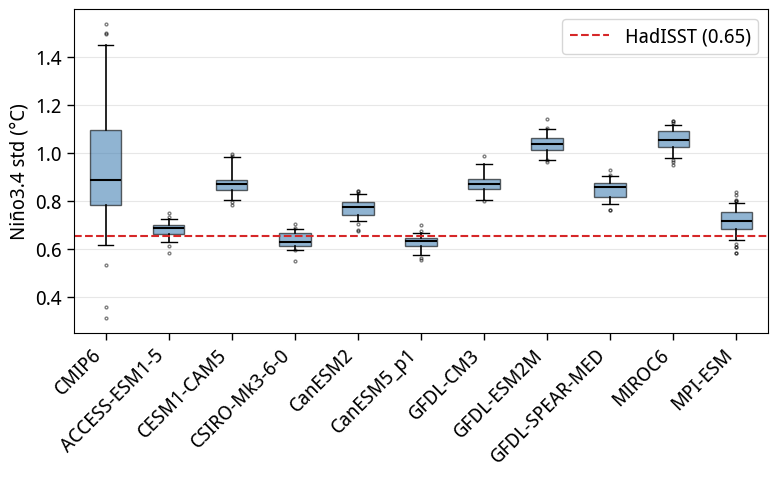

In [27]:
fig, ax = plt.subplots(figsize=(8, 5))

# Build data and positions
labels   = ['CMIP6'] + smile_models
data     = [cmip6_nino34_std.values] + \
           [smile_nino34_std[m].values for m in smile_models]

bp = ax.boxplot(data, patch_artist=True, notch=False, whis=[5,95],
                medianprops=dict(color='k', lw=1.5),
                boxprops=dict(facecolor='steelblue', alpha=0.6),
                whiskerprops=dict(lw=1.2),
                flierprops=dict(marker='.', markersize=4, alpha=0.5),)

# Obs line
ax.axhline(obs_nino34_std, color='tab:red', lw=1.5, 
           linestyle='--', label=f'HadISST ({obs_nino34_std:.2f})')

ax.set_xticks(range(1, len(labels) + 1))
ax.set_xticklabels(labels, rotation=45, ha='right')
ax.set_ylabel('Niño3.4 std (°C)')
# ax.set_title('Niño3.4 amplitude — CMIP6 models and SMILEs vs observations')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

In [28]:
ar6_regions = regionmask.defined_regions.ar6.land

ar6_mask_obs   = ar6_regions.mask(tas_obs.lon,   tas_obs.lat)
ar6_mask_rean  = ar6_regions.mask(pr_rean.lon,   pr_rean.lat)
ar6_mask_cmip6 = ar6_regions.mask(tas_cmip6.lon, tas_cmip6.lat)
ar6_mask_smile = ar6_regions.mask(tas_smile['ACCESS-ESM1-5'].lon,
                                   tas_smile['ACCESS-ESM1-5'].lat)

def extract_region(da, mask, region_num):
    return da.where(mask == region_num).mean(['lat', 'lon'])

In [29]:
def rolling_composite(da, cond_en, cond_ln,
                       start=1900, end=2014, duration=30, gap=1):
    en_means, ln_means, yrs = [], [], []
    
    for yr in range(start, end - duration + 2, gap):
        win        = slice(str(yr), str(yr + duration - 1))
        en_sub     = da.sel(time=win).where(cond_en.sel(time=win), drop=True)
        ln_sub     = da.sel(time=win).where(cond_ln.sel(time=win), drop=True)
        
        en_means.append(float(en_sub.mean('time', skipna=True)) 
                        if en_sub.sizes['time'] > 2 else np.nan)
        ln_means.append(float(ln_sub.mean('time', skipna=True)) 
                        if ln_sub.sizes['time'] > 2 else np.nan)
        yrs.append(yr + duration - 1)
    
    return np.array(yrs), np.array(en_means), np.array(ln_means)

In [30]:
all_abbrevs = {r.abbrev: r.number for r in ar6_regions}

In [31]:
baseline = slice('1950', '2014')
obs_std  = float(nino34_obs['ts'].sel(time=baseline).std('time'))

cond_en_obs  = nino34_obs['ts'] >  0.5 * obs_std
cond_ln_obs  = nino34_obs['ts'] < -0.5 * obs_std
cond_neu_obs = (nino34_obs['ts'] >= -0.25 * obs_std) & (nino34_obs['ts'] <= 0.25 * obs_std)

cmip6_std    = nino34_cmip6.sel(time=baseline).std('time')
cond_en_cmip6  = nino34_cmip6 >  0.5 * cmip6_std
cond_ln_cmip6  = nino34_cmip6 < -0.5 * cmip6_std
cond_neu_cmip6 = (nino34_cmip6 >= -0.25 * cmip6_std) & (nino34_cmip6 <= 0.25 * cmip6_std)

cond_en_smile, cond_ln_smile, cond_neu_smile = {}, {}, {}
for m in tqdm(smile_models, desc='ENSO masks SMILEs'):
    smile_std         = nino34_smile[m].sel(time=baseline).std('time')
    cond_en_smile[m]  = nino34_smile[m] >  0.5 * smile_std
    cond_ln_smile[m]  = nino34_smile[m] < -0.5 * smile_std
    cond_neu_smile[m] = (nino34_smile[m] >= -0.25 * smile_std) & \
                        (nino34_smile[m] <=  0.25 * smile_std)

ENSO masks SMILEs:   0%|          | 0/10 [00:00<?, ?it/s]

In [32]:
baseline = slice('1950', '2014')
fut1     = slice('2070', '2100')
fut2     = slice('2030', '2060')

pr_records  = []
tas_records = []

for abbrev, rnum in tqdm(all_abbrevs.items(), desc='Regional composites'):

    # --- Extract regional means ---
    pr_r        = extract_region(pr_rean['pr'],   ar6_mask_rean,  rnum)
    pr_r        = pr_r / float(pr_r.std('time', skipna=True))
    pr_cmip6_r  = extract_region(pr_cmip6['pr'],  ar6_mask_cmip6, rnum)
    pr_cmip6_r  = pr_cmip6_r / pr_cmip6_r.std('time', skipna=True)
    tas_r       = extract_region(tas_obs['tas'],  ar6_mask_obs,   rnum)
    tas_cmip6_r = extract_region(tas_cmip6['ts'], ar6_mask_cmip6, rnum)

    # --- Obs baseline composites ---
    def obs_comp(da, cond):
        return float(da.sel(time=baseline)
                       .where(cond.sel(time=baseline), drop=True)
                       .mean('time', skipna=True))

    pr_en_base  = obs_comp(pr_r,  cond_en_obs)
    pr_ln_base  = obs_comp(pr_r,  cond_ln_obs)
    tas_en_base = obs_comp(tas_r, cond_en_obs)
    tas_ln_base = obs_comp(tas_r, cond_ln_obs)

    # --- Obs rolling 30-year ---
    _, pr_en_roll,  pr_ln_roll  = rolling_composite(pr_r,  cond_en_obs, cond_ln_obs)
    _, tas_en_roll, tas_ln_roll = rolling_composite(tas_r, cond_en_obs, cond_ln_obs)

    # --- CMIP6 future composites ---
    def cmip6_comp(da, cond, period):
        return float(da.where(cond).sel(time=period)
                       .mean(['time', 'model'], skipna=True))

    pr_en_fut1  = cmip6_comp(pr_cmip6_r,  cond_en_cmip6, fut1)
    pr_en_fut2  = cmip6_comp(pr_cmip6_r,  cond_en_cmip6, fut2)
    pr_ln_fut1  = cmip6_comp(pr_cmip6_r,  cond_ln_cmip6, fut1)
    pr_ln_fut2  = cmip6_comp(pr_cmip6_r,  cond_ln_cmip6, fut2)
    tas_en_fut1 = cmip6_comp(tas_cmip6_r, cond_en_cmip6, fut1)
    tas_en_fut2 = cmip6_comp(tas_cmip6_r, cond_en_cmip6, fut2)
    tas_ln_fut1 = cmip6_comp(tas_cmip6_r, cond_ln_cmip6, fut1)
    tas_ln_fut2 = cmip6_comp(tas_cmip6_r, cond_ln_cmip6, fut2)

    # --- SMILE future composites — single loop for both PR and TAS ---
    pr_smile_en_fut1,  pr_smile_ln_fut1  = [], []
    pr_smile_en_fut2,  pr_smile_ln_fut2  = [], []
    tas_smile_en_fut1, tas_smile_ln_fut1 = [], []
    tas_smile_en_fut2, tas_smile_ln_fut2 = [], []

    for m in smile_models:
        pr_sm  = extract_region(pr_smile[m]['pr'],   ar6_mask_smile, rnum)
        pr_sm  = pr_sm / pr_sm.std('time', skipna=True)
        tas_sm = extract_region(tas_smile[m]['ts'],  ar6_mask_smile, rnum)

        def smile_comp(da, cond, period):
            return float(da.where(cond).sel(time=period)
                           .mean(['time', 'model'], skipna=True))

        pr_smile_en_fut1.append(smile_comp(pr_sm,  cond_en_smile[m], fut1))
        pr_smile_en_fut2.append(smile_comp(pr_sm,  cond_en_smile[m], fut2))
        pr_smile_ln_fut1.append(smile_comp(pr_sm,  cond_ln_smile[m], fut1))
        pr_smile_ln_fut2.append(smile_comp(pr_sm,  cond_ln_smile[m], fut2))
        tas_smile_en_fut1.append(smile_comp(tas_sm, cond_en_smile[m], fut1))
        tas_smile_en_fut2.append(smile_comp(tas_sm, cond_en_smile[m], fut2))
        tas_smile_ln_fut1.append(smile_comp(tas_sm, cond_ln_smile[m], fut1))
        tas_smile_ln_fut2.append(smile_comp(tas_sm, cond_ln_smile[m], fut2))

    # --- Store ---
    pr_records.append(dict(
        abbrev        = abbrev,
        name          = ar6_regions[rnum].name,
        pr_str        = (abs(pr_en_base) + abs(pr_ln_base)) / 2,
        en_base       = pr_en_base,   ln_base       = pr_ln_base,
        en_roll       = pr_en_roll,   ln_roll       = pr_ln_roll,
        en_fut1       = pr_en_fut1,   en_fut2       = pr_en_fut2,
        ln_fut1       = pr_ln_fut1,   ln_fut2       = pr_ln_fut2,
        smile_en_fut1 = pr_smile_en_fut1, smile_en_fut2 = pr_smile_en_fut2,
        smile_ln_fut1 = pr_smile_ln_fut1, smile_ln_fut2 = pr_smile_ln_fut2,
    ))

    tas_records.append(dict(
        abbrev        = abbrev,
        name          = ar6_regions[rnum].name,
        tas_str       = (abs(tas_en_base) + abs(tas_ln_base)) / 2,
        en_base       = tas_en_base,  ln_base       = tas_ln_base,
        en_roll       = tas_en_roll,  ln_roll       = tas_ln_roll,
        en_fut1       = tas_en_fut1,  en_fut2       = tas_en_fut2,
        ln_fut1       = tas_ln_fut1,  ln_fut2       = tas_ln_fut2,
        smile_en_fut1 = tas_smile_en_fut1, smile_en_fut2 = tas_smile_en_fut2,
        smile_ln_fut1 = tas_smile_ln_fut1, smile_ln_fut2 = tas_smile_ln_fut2,
    ))

df_pr  = pd.DataFrame(pr_records)
df_tas = pd.DataFrame(tas_records)

print("PR regions:", len(df_pr))
print("TAS regions:", len(df_tas))
print(df_pr[['abbrev', 'name', 'pr_str', 'en_base', 'ln_base']].head())

Regional composites:   0%|          | 0/46 [00:00<?, ?it/s]

PR regions: 46
TAS regions: 46
  abbrev               name    pr_str   en_base   ln_base
0    GIC  Greenland/Iceland  0.101998 -0.163553 -0.040444
1    NWN  N.W.North-America  0.342284 -0.420325 -0.264243
2    NEN  N.E.North-America  0.057383 -0.106335 -0.008431
3    WNA    W.North-America  0.130145  0.204713  0.055578
4    CNA    C.North-America  0.236055  0.303149 -0.168960


In [33]:
# Filter by baseline teleconnection strength
pr_threshold  = 0.2
tas_threshold = 0.1

df_pr_filt  = df_pr[df_pr['pr_str']   > pr_threshold].sort_values('pr_str',  ascending=False)
df_tas_filt = df_tas[df_tas['tas_str'] > tas_threshold].sort_values('tas_str', ascending=False)

print(f"PR regions after filter:  {len(df_pr_filt)}")
print(f"TAS regions after filter: {len(df_tas_filt)}")
print(df_pr_filt[['abbrev', 'name', 'pr_str']].to_string())

PR regions after filter:  29
TAS regions after filter: 23
   abbrev               name    pr_str
38    SEA           S.E.Asia  1.092296
39    NAU        N.Australia  1.038596
10    NSA    N.South-America  0.867249
32    WCA           W.C.Asia  0.779116
40    CAU        C.Australia  0.746476
41    EAU        E.Australia  0.695905
37    SAS             S.Asia  0.647100
33    ECA           E.C.Asia  0.599552
42    SAU        S.Australia  0.548296
43     NZ        New-Zealand  0.539443
11    NES  N.E.South-America  0.521170
14    SES  S.E.South-America  0.461003
26   ESAF  E.Southern-Africa  0.449323
29    WSB          W.Siberia  0.388770
34    TIB    Tibetan-Plateau  0.385165
7     SCA  S.Central-America  0.373473
9     NWS  N.W.South-America  0.354399
6     NCA  N.Central-America  0.347578
1     NWN  N.W.North-America  0.342284
19    MED      Mediterranean  0.341832
44    EAN       E.Antarctica  0.303281
25   WSAF  W.Southern-Africa  0.296962
13    SWS  S.W.South-America  0.269679
30    

In [34]:
df_pr_plot  = df_pr_filt.head(20)
df_tas_plot = df_tas_filt.head(20)

In [35]:
def plot_regional_boxplot(df, var, title, xlabel):
    fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=False)
    
    phases    = [('en', 'El Niño', 'tab:red'), ('ln', 'La Niña', 'tab:blue')]
    periods   = [('fut1', '2070–2100', 'o'), ('fut2', '2030–2060', 's')]
    
    for ax, (phase, phase_label, color) in zip(axes, phases):
        
        regions   = df['abbrev'].tolist()
        n_regions = len(regions)
        positions = np.arange(n_regions)

        # --- Obs rolling boxplot ---
        roll_data = [df.loc[df.abbrev == r, f'{phase}_roll'].values[0] 
                     for r in regions]
        bp = ax.boxplot(
            roll_data,
            positions  = positions,
            widths     = 0.4,
            patch_artist = True,
            boxprops   = dict(facecolor='lightgrey', alpha=0.8),
            medianprops= dict(color='k', lw=1.5),
            whiskerprops=dict(lw=1.0),
            flierprops = dict(marker='.', markersize=3, alpha=0.4),
            zorder     = 2
        )

        # --- Obs baseline marker ---
        base_vals = [float(df.loc[df.abbrev == r, f'{phase}_base'].values[0])
                     for r in regions]
        ax.scatter(positions, base_vals, color='k', marker='_',
                   s=200, lw=2, zorder=4, label='Obs baseline')

        # --- CMIP6 future markers ---
        for period_key, period_label, marker in periods:
            fut_vals = [float(df.loc[df.abbrev == r, f'{phase}_{period_key}'].values[0])
                        for r in regions]
            ax.scatter(positions, fut_vals, color=color, marker=marker,
                       s=60, zorder=5, label=f'CMIP6 {period_label}')

        # --- SMILE future markers ---
        for period_key, period_label, marker in periods:
            smile_vals = [df.loc[df.abbrev == r, f'smile_{phase}_{period_key}'].values[0]
                          for r in regions]
            # Show as small scatter per SMILE model
            for i, (r, vals) in enumerate(zip(regions, smile_vals)):
                ax.scatter(
                    np.full(len(vals), i) + 0.15,
                    vals,
                    color=color, marker=marker,
                    s=20, alpha=0.4, zorder=3,
                )

        # --- Zero line ---
        ax.axhline(0, color='k', lw=0.5, linestyle=':')

        ax.set_xticks(positions)
        ax.set_xticklabels(regions, rotation=45, ha='right')
        ax.set_ylabel(xlabel)
        ax.set_title(f'{phase_label} — {title}')
        ax.grid(True, alpha=0.3, axis='y')

        if ax == axes[0]:
            ax.legend(fontsize=8, ncol=4, loc='upper right')

    plt.tight_layout()
    plt.show()


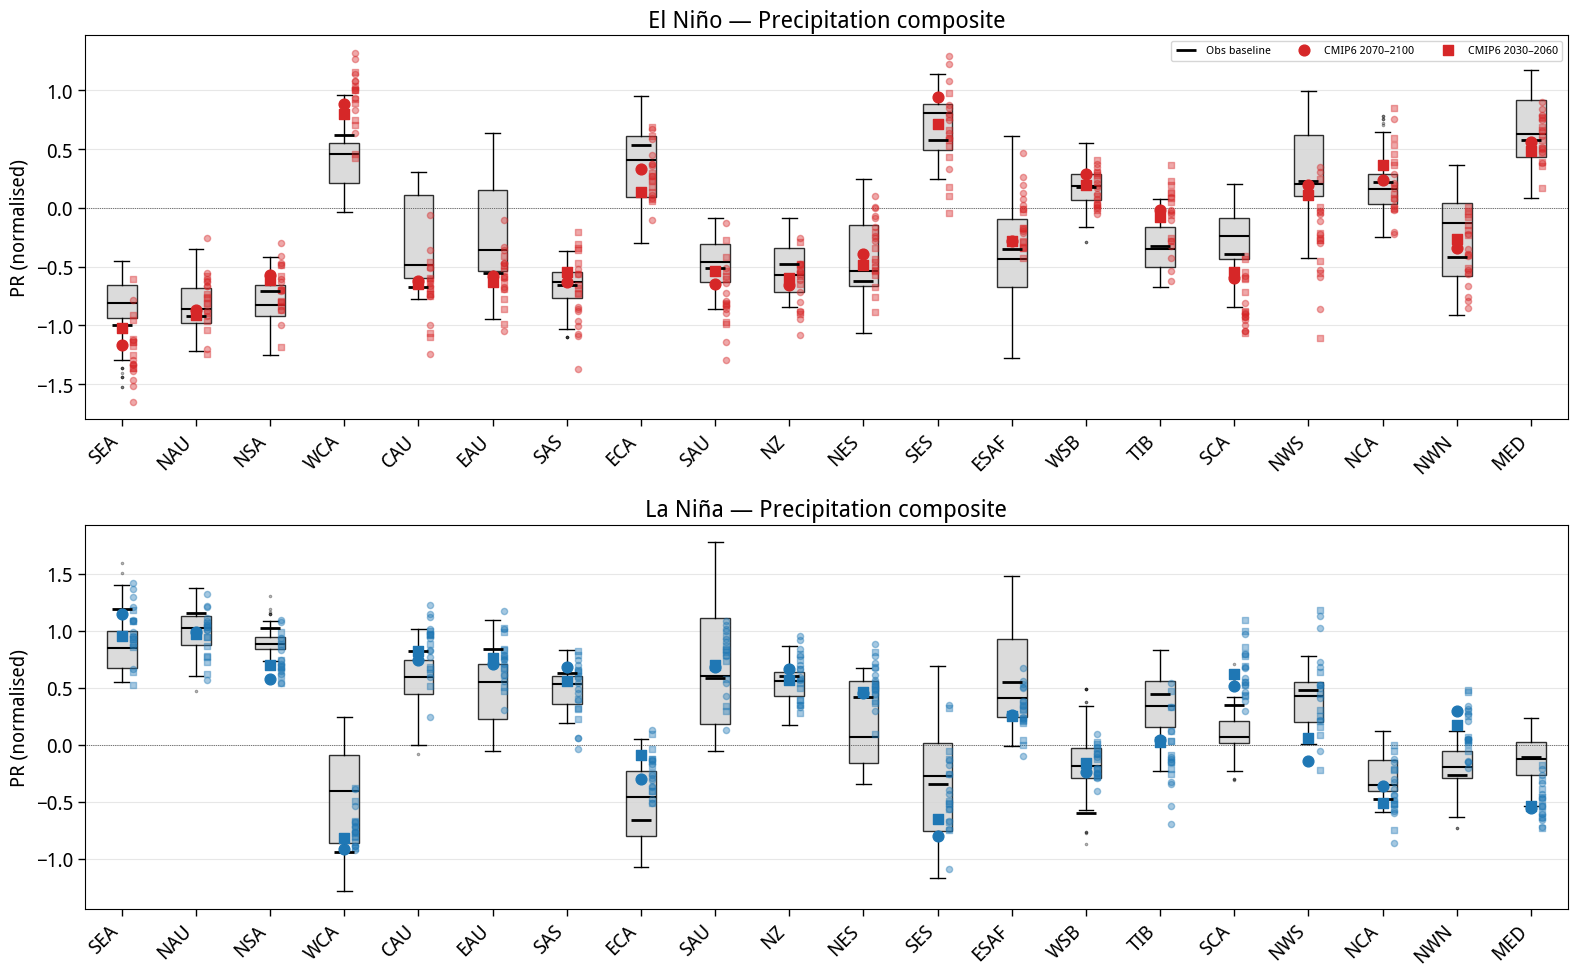

In [36]:
# PR figure
plot_regional_boxplot(df_pr_plot,  'pr',  'Precipitation composite', 'PR (normalised)')

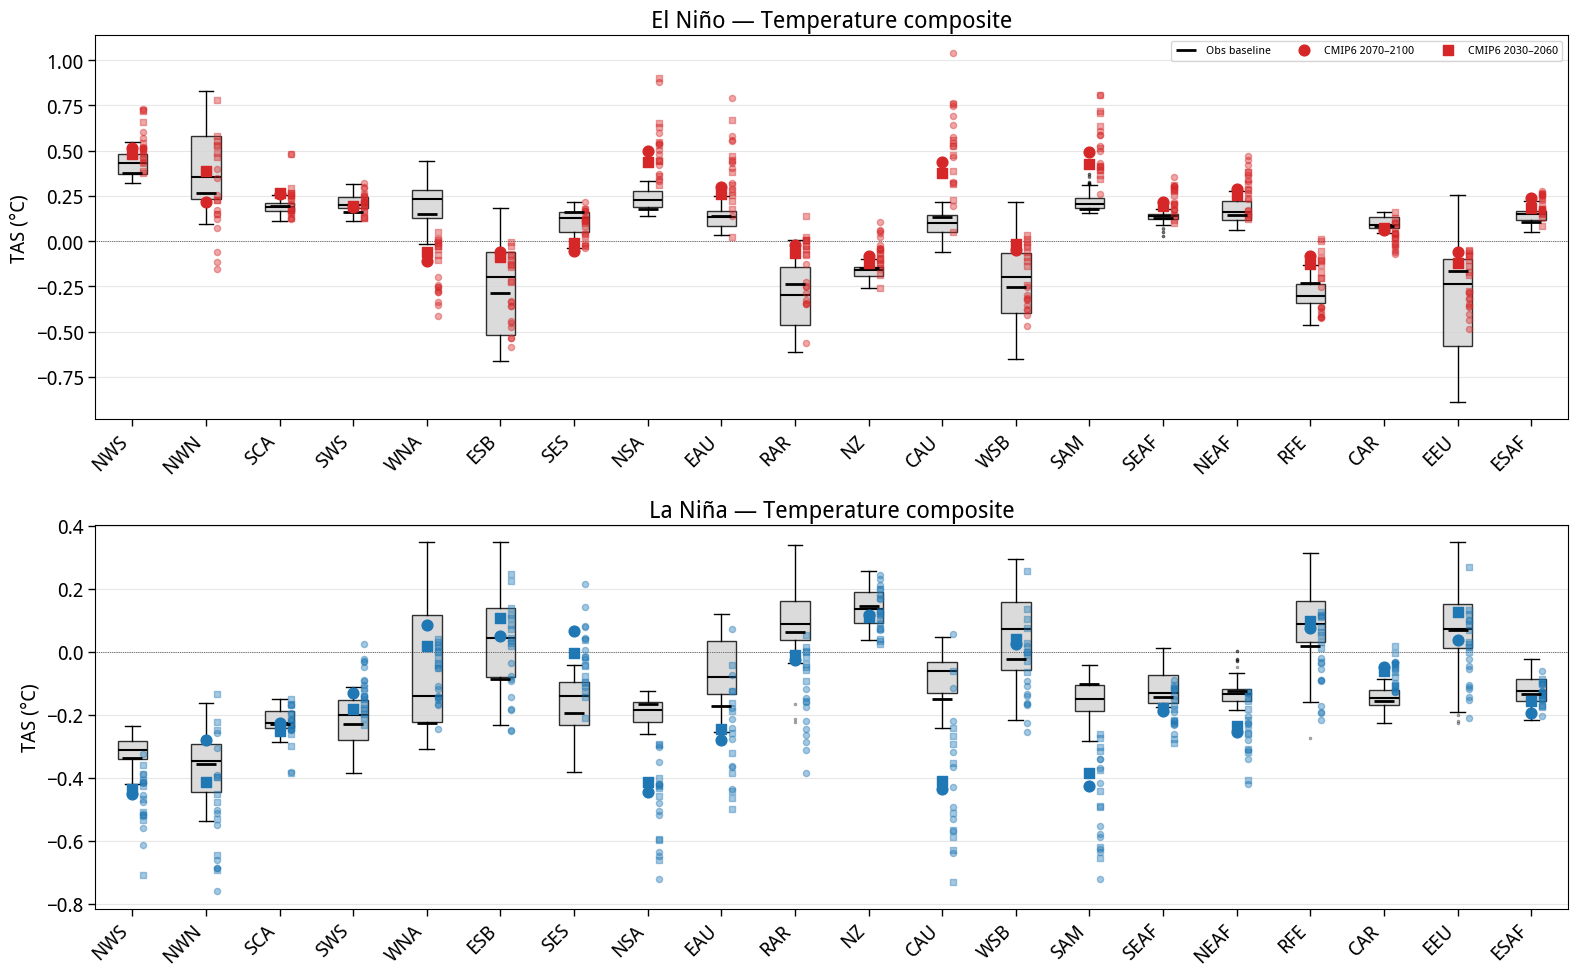

In [37]:


# TAS figure
plot_regional_boxplot(df_tas_plot, 'tas', 'Temperature composite',   'TAS (°C)')